In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df=df = pd.read_excel('StudentsPerformance.xlsx')
df.info()
print("Dataset Imported Successfully!")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB
Dataset Imported Successfully!


In [4]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [5]:
df.tail()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


In [6]:
print("Dataset Shape:", df.shape)
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Dataset Shape: (1000, 8)
Total Rows: 1000
Total Columns: 8


In [7]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [9]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


In [10]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [11]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [12]:
score_columns = [
    "math score",
    "reading score",
    "writing score"
]

scores = df[score_columns]

scores.head()

,math score,reading score,writing score
0,72,72,74
1,69,90,88
2,90,95,93
3,47,57,44
4,76,78,75


In [13]:
average_scores = scores.mean()

print("Average Scores in Each Subject:")
print(average_scores)

Average Scores in Each Subject:
math score       66.089
reading score    69.169
writing score    68.054
dtype: float64


In [14]:
print("Highest Marks:")
print(scores.max())

print("\nLowest Marks:")
print(scores.min())

Highest Marks:
math score       100
reading score    100
writing score    100
dtype: int64

Lowest Marks:
math score        0
reading score    17
writing score    10
dtype: int64


In [15]:
df["average score"] = scores.mean(axis=1)

print("Overall Average Score:")
print(df["average score"].mean())

Overall Average Score:
67.77066666666666


In [16]:
top_students = df.nlargest(5, "average score")

top_students[
    ["math score", "reading score", "writing score", "average score"]
]

,math score,reading score,writing score,average score
458,100,100,100,100.000000
916,100,100,100,100.000000
962,100,100,100,100.000000
114,99,100,100,99.666667
179,97,100,100,99.000000


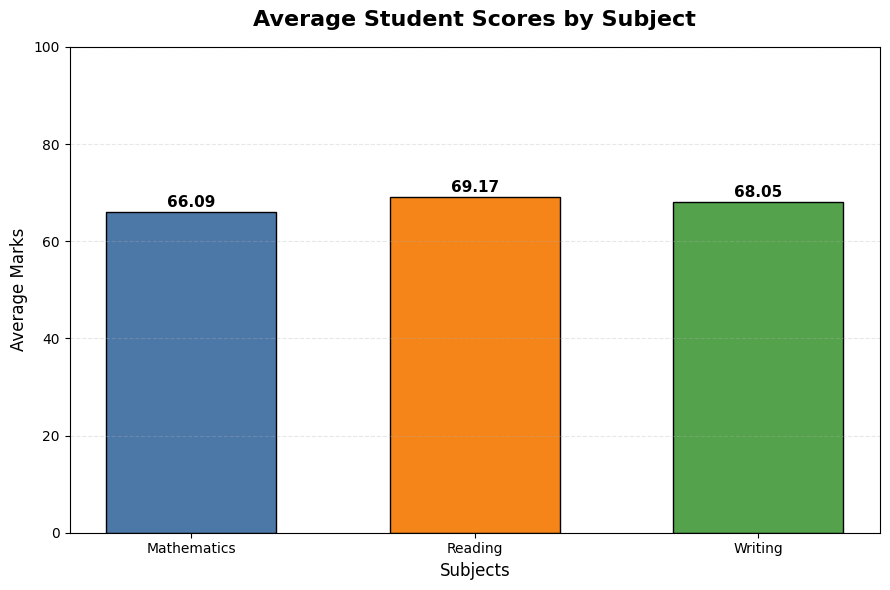

In [20]:

# Calculate average scores for each subject
average_scores = df[["math score", "reading score", "writing score"]].mean()

# Create the bar chart
plt.figure(figsize=(9, 6))

bars = plt.bar(
    ["Mathematics", "Reading", "Writing"],
    average_scores.values,
    color=["#4C78A8", "#F58518", "#54A24B"],
    width=0.6,
    edgecolor="black"
)

# Add score values above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f}",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

# Add chart title and labels
plt.title("Average Student Scores by Subject",
          fontsize=16, fontweight="bold", pad=15)

plt.xlabel("Subjects", fontsize=12)
plt.ylabel("Average Marks", fontsize=12)

plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


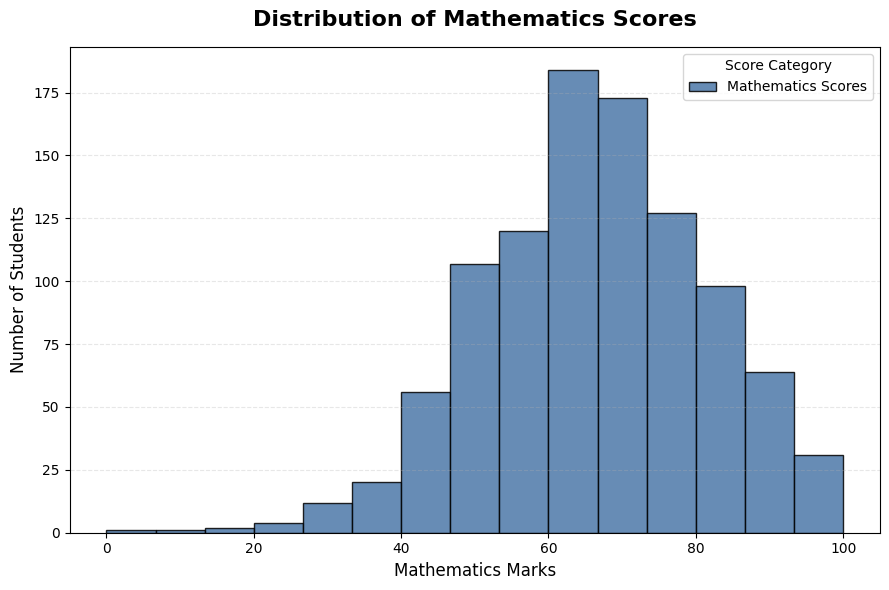

In [24]:

# Create histogram for Mathematics scores
plt.figure(figsize=(9, 6))

plt.hist(
    df["math score"],
    bins=15,
    color="#4C78A8",
    edgecolor="black",
    alpha=0.85,
    label="Mathematics Scores"
)

# Add title and labels
plt.title("Distribution of Mathematics Scores",
          fontsize=16, fontweight="bold", pad=15)

plt.xlabel("Mathematics Marks", fontsize=12)
plt.ylabel("Number of Students", fontsize=12)

# Add grid and legend
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.legend(title="Score Category")

plt.tight_layout()
plt.show()


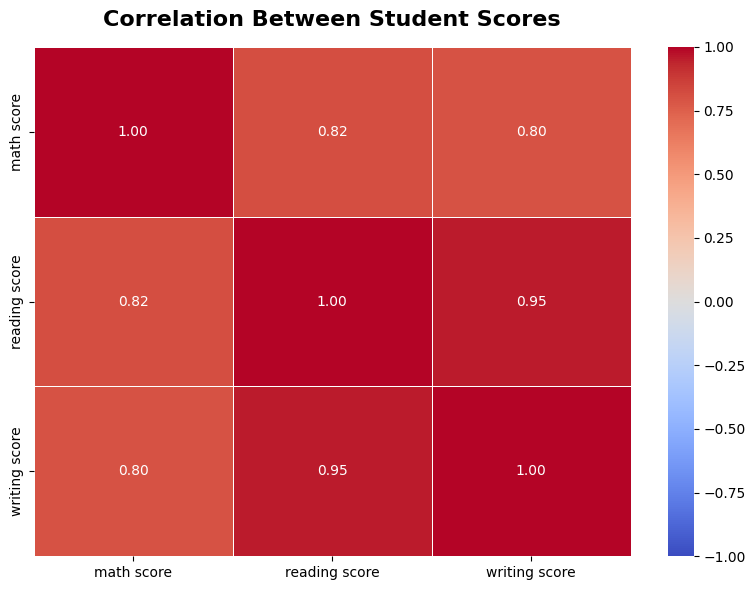

In [26]:

import seaborn as sns
# Select numerical score columns
score_data = df[["math score", "reading score", "writing score"]]

# Calculate correlation
correlation = score_data.corr()

# Create heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Student Scores",
          fontsize=16, fontweight="bold", pad=15)

plt.tight_layout()
plt.show()
